# 02 · H₂O: a fragment frame with a heavy atom

The covalent diatomics-in-molecules (DIM) frame builds water from eight OH states and the H₂ singlet/triplet,
with **no H₂O data**. It gets the limits exactly right and fails at equilibrium, because ionic O⁻H⁺ structures
are missing from the frame. The notebook measures how much learned corrections recover, and where they live:

| Model | Learned part |
|---|---|
| `physics prior` | none (covalent DIM) |
| `framed (mixing)` | OH term-mixing angles (³P/¹D, ¹D/¹S) as functions of r: a fragment-level correction |
| `framed CDNN` | the above plus a dense 9 × 9 correction inside the DIM frame, switched off when either H leaves |
| `framed + KRR` | DIM prior + kernel ridge on the residual |
| `KRR` | kernel ridge on the energy, no physics |

All energies: frozen-core FCI/6-31G, eV relative to O(³P) + 2H.

In [1]:
# ---------------- controls ----------------
MODELS   = ['framed (mixing)', 'framed CDNN', 'framed + KRR', 'KRR']
N_TRAIN  = [10, 40, 80]
SPLITS   = 2
EPOCHS   = 2000
RESTARTS = 2

In [2]:
import sys, time, numpy as np, torch, matplotlib.pyplot as plt
sys.path.insert(0, '..')                      # the diabml package lives one level up
from diabml import RefSet
from diabml.units import EV_KCAL
from diabml import plotting as P, metrics as M
from diabml.models import CDNN, IndependentNN, FramedModel, KRR, train
P.style()
torch.set_num_threads(2)
DATA = '../data/'
from diabml.frames.dim_oh import DIMWaterFrame, bond_additivity, h2o_invariants
oh, h2, w = RefSet.load(DATA + 'oh_curves.npz'), RefSet.load(DATA + 'h2_631g.npz'), RefSet.load(DATA + 'h2o.npz')
frame = DIMWaterFrame(oh, h2)
frame_g = DIMWaterFrame(oh, h2, generic=True)
t0 = time.time(); E_dim = frame.prior_energies(w.coords)[:, 0]; print(f'DIM prior for {len(w)} geometries: {time.time() - t0:.0f} s')
E_add = bond_additivity(w.coords, frame)
for k, E in [('covalent DIM', E_dim), ('bond additivity', E_add)]:
    print(f'{k:16s} RMSE {M.rmse_kcal(E[:, None], w.energies)[0]:.1f} kcal/mol')

DIM prior for 149 geometries: 1 s
covalent DIM     RMSE 24.8 kcal/mol
bond additivity  RMSE 25.4 kcal/mol


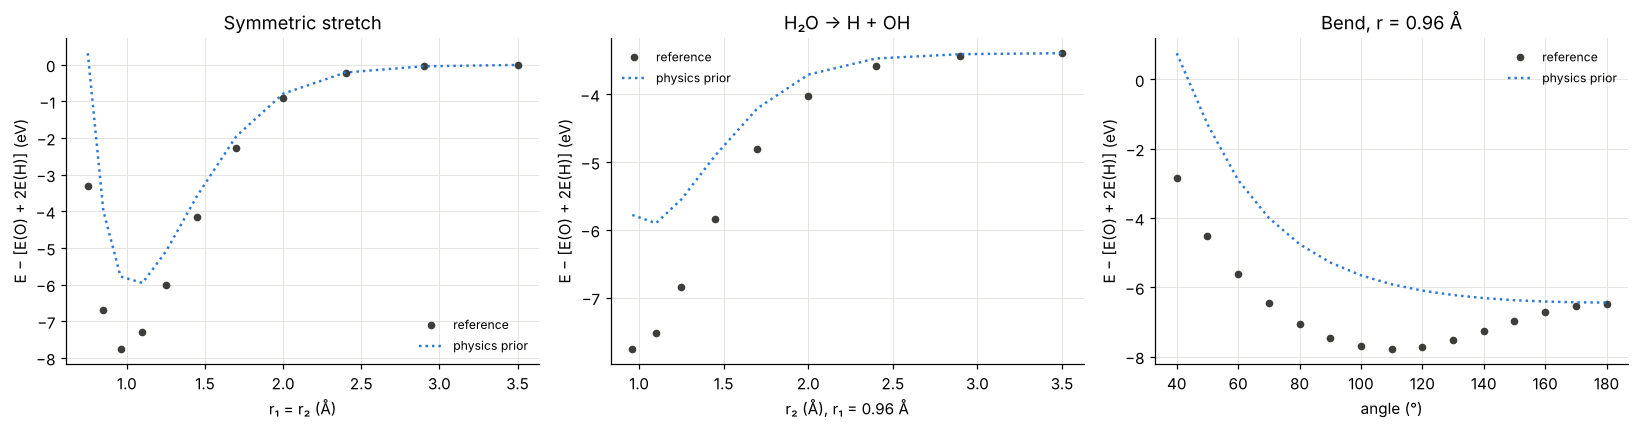

In [3]:
tag = w.extra['tag']
def scan(mask, col):
    i = np.where(mask)[0]; return i[np.argsort(w.coords[i, col])]
scans = [(scan((tag == 'grid') & (w.coords[:, 0] == w.coords[:, 1]), 0), 0, 'r₁ = r₂ (Å)', 'Symmetric stretch'),
         (scan((tag == 'grid') & (w.coords[:, 0] == 0.96), 1), 1, 'r₂ (Å), r₁ = 0.96 Å', 'H₂O → H + OH'),
         (scan(tag == 'bend096', 2), 2, 'angle (°)', 'Bend, r = 0.96 Å')]
def show(preds, title=''):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (i, col, xl, t) in zip(axes, scans):
        P.cut_plot(w.coords[i, col], w.energies[i], {k: E[i][:, None] if E.ndim == 1 else E[i] for k, E in preds.items()},
                   xl, 'E − [E(O) + 2E(H)] (eV)', title=f'{t}{title}', ax=ax)
    plt.tight_layout(); plt.show()
show({'physics prior': E_dim})

## Learning the rest of water

For each training size, random splits of all 149 geometries: train on *n*, validate on 20, test on the rest.

split 0 done (89 s)


split 1 done (179 s)
framed (mixing)  n=10:  20.9  n=40:  20.8  n=80:  17.6
framed CDNN      n=10:  16.1  n=40:   9.4  n=80:   1.5
framed + KRR     n=10:  18.1  n=40:  13.1  n=80:   4.7
KRR              n=10:  33.3  n=40:  32.0  n=80:   5.1


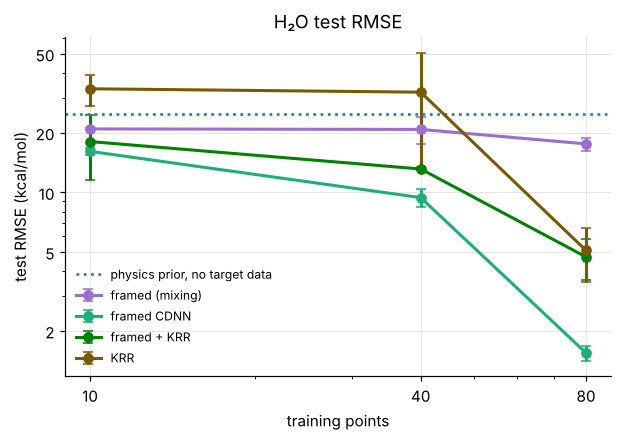

In [4]:
FEAT = h2o_invariants
res = {k: {n: [] for n in N_TRAIN} for k in MODELS}
keep = {}
t0 = time.time()
for s in range(SPLITS):
    for n in N_TRAIN:
        tr, va, te = w.split(n, 20, seed=s)
        for k in MODELS:
            if k == 'framed (mixing)':
                m = train(FramedModel(frame, 1, hidden=(16, 16)), w.coords[tr], w.energies[tr], w.coords[va], w.energies[va],
                          epochs=EPOCHS, lr=3e-3, restarts=RESTARTS); pred = m.predict(w.coords)
            elif k == 'framed CDNN':
                m = train(FramedModel(frame_g, 1, hidden=(32, 32)), w.coords[tr], w.energies[tr], w.coords[va], w.energies[va],
                          epochs=EPOCHS, lr=3e-3, restarts=RESTARTS); pred = m.predict(w.coords)
            elif k == 'framed + KRR':
                kr = KRR(FEAT).fit(w.coords[tr], w.energies[tr, 0] - E_dim[tr]); pred = (E_dim + kr.predict(w.coords))[:, None]
            else:
                kr = KRR(FEAT).fit(w.coords[tr], w.energies[tr, 0]); pred = kr.predict(w.coords)[:, None]
            res[k][n].append(M.rmse_kcal(pred[te], w.energies[te])[0])
            if s == 0 and n == N_TRAIN[-1]:
                keep[k] = pred
    print(f'split {s} done ({time.time() - t0:.0f} s)')
for k in MODELS:
    print(f'{k:16s}', '  '.join(f'n={n}: {np.mean(res[k][n]):5.1f}' for n in N_TRAIN))
P.learning_curves(N_TRAIN, {k: [res[k][n] for n in N_TRAIN] for k in MODELS},
                  baseline=M.rmse_kcal(E_dim[:, None], w.energies)[0], title='H₂O test RMSE'); plt.show()

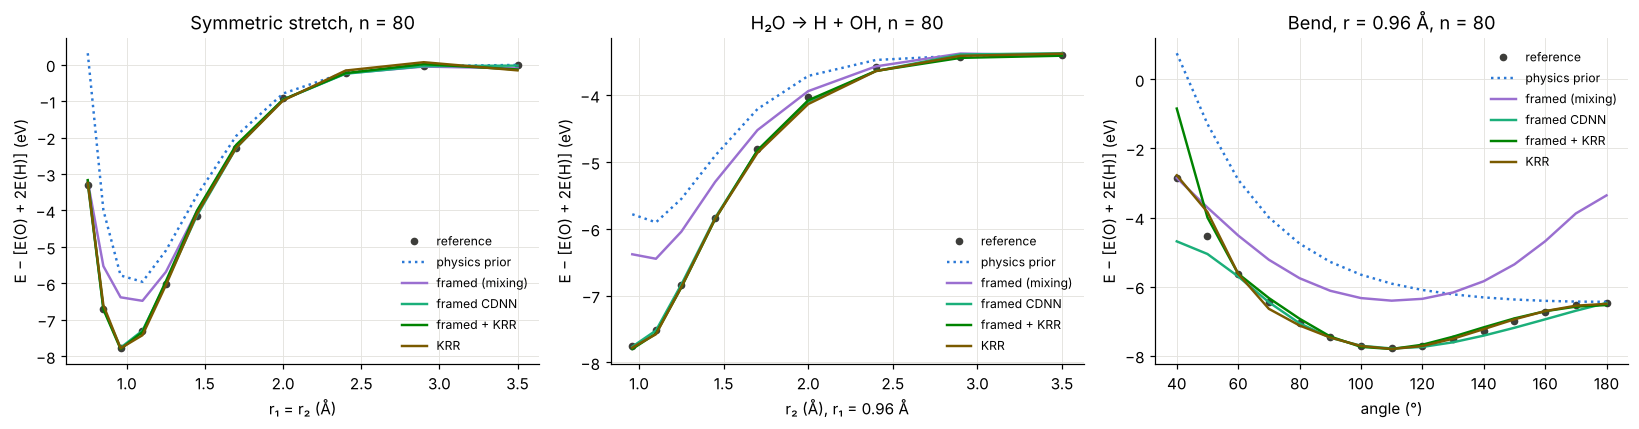

In [5]:
show({'physics prior': E_dim, **keep}, f', n = {N_TRAIN[-1]}')

**Reading the results.** The frame gets the H + OH channel right with no water data, and mixing angles alone barely
help, because the missing physics (ionic O⁻H⁺ structures) is outside the covalent space. Corrections that act on the
whole matrix or the energy recover much more, and starting from the DIM prior beats learning from scratch.
The natural next step in the backend is an **ionic DIM frame**: add O⁻ + H⁺ structures, with OH⁻ and H₂⁺ fragment
curves supplying their energies (the electron ladder in fragment form).